In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)


/kaggle/input/competitions/playground-series-s6e11/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e11/train.csv
/kaggle/input/competitions/playground-series-s6e11/test.csv


In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, train_test_split , cross_val_score, GridSearchCV
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

In [3]:
data = pd.read_csv('/kaggle/input/competitions/playground-series-s6e11/train.csv')
sam_sub = pd.read_csv('/kaggle/input/competitions/playground-series-s6e11/sample_submission.csv')
kagg_test = pd.read_csv('/kaggle/input/competitions/playground-series-s6e11/test.csv')


In [4]:
na_analysis = pd.DataFrame(
    {
        'total_na': data.isna().sum(),
        'total_na_per' : (data.isna().sum()/data.shape[0])*100
    }
)
na_analysis.describe()

,total_na,total_na_per
count,26.0,26.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,0.0,0.0
max,0.0,0.0


In [5]:
data.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


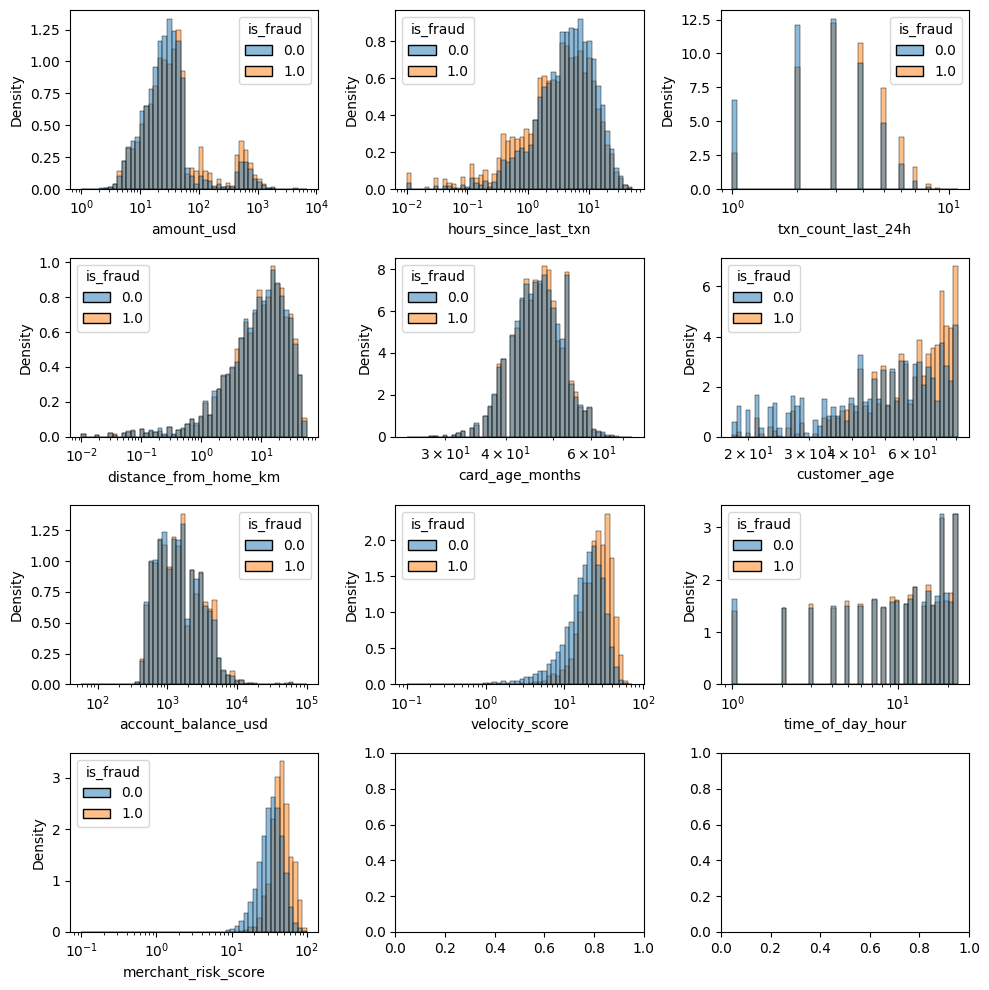

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(10, 10))
axes = axes.flatten()
for i, col in enumerate(['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 
            'card_age_months', 'customer_age', 'account_balance_usd', 'velocity_score',
            'time_of_day_hour', 'merchant_risk_score']):
    sns.histplot(data=data, x=col, hue='is_fraud', stat='density', common_norm=False, log_scale=True, bins=50, ax=axes[i])
plt.tight_layout()
plt.show()

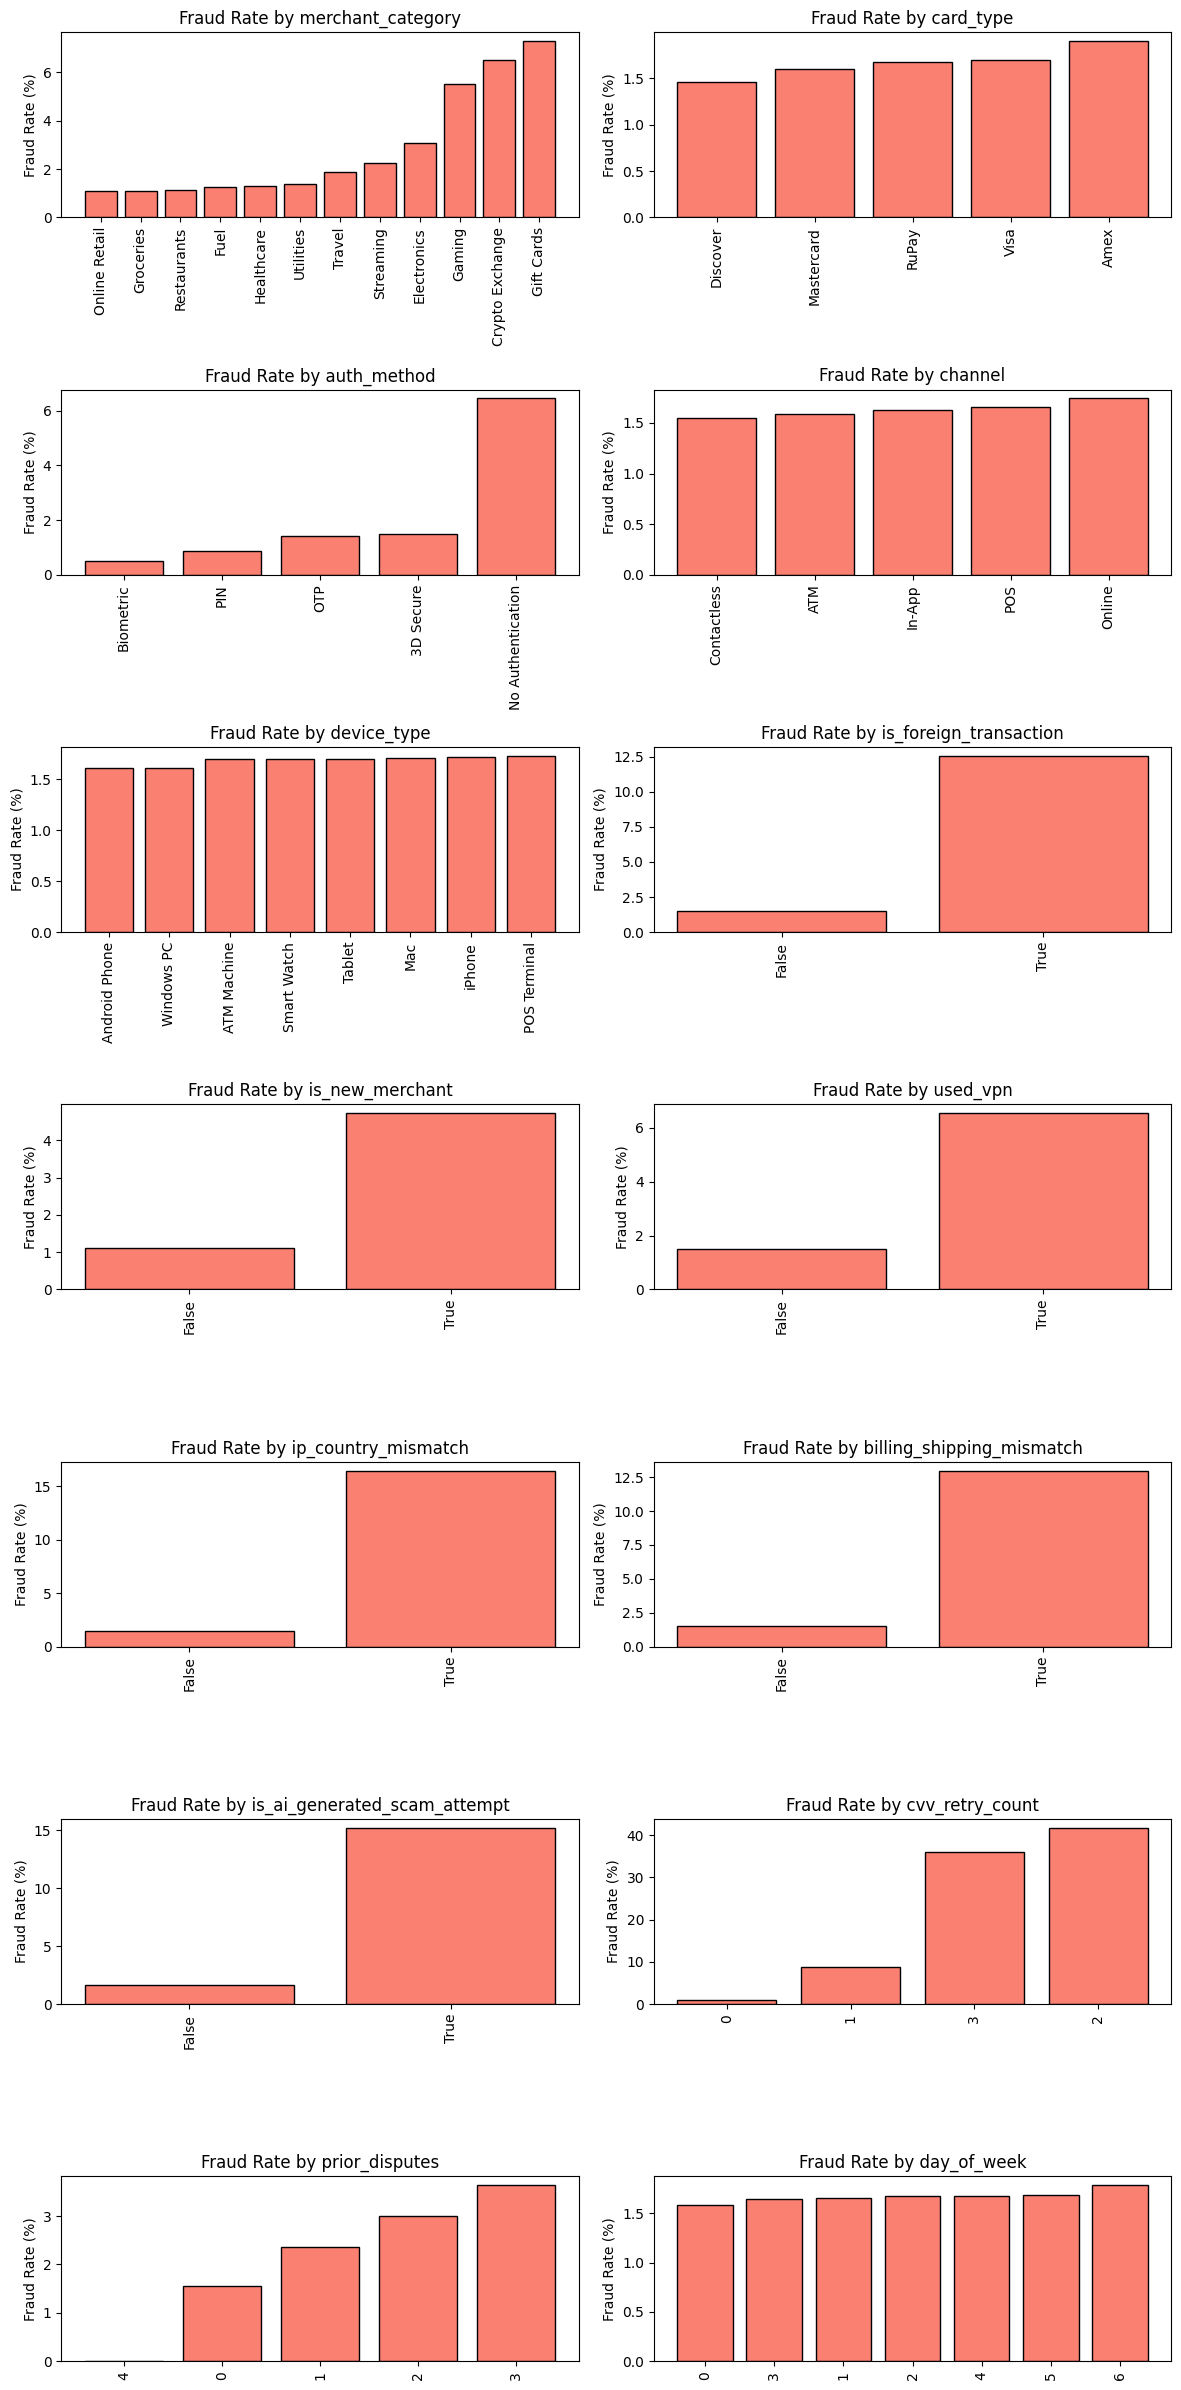

In [7]:
fig, axes = plt.subplots(7, 2, figsize=(12, 24))
axes = axes.flatten()
for i, col in enumerate(['merchant_category', 'card_type', 'auth_method', 'channel',
            'device_type', 'is_foreign_transaction', 'is_new_merchant',	
            'used_vpn',	'ip_country_mismatch', 'billing_shipping_mismatch',
            'is_ai_generated_scam_attempt', 'cvv_retry_count', 'prior_disputes', 'day_of_week']):
    agg = pd.DataFrame(data.groupby(by=col)['is_fraud'].mean().mul(100).sort_values().reset_index())
    axes[i].bar(agg[col].astype(str), agg['is_fraud'], color='salmon', edgecolor='black')
    axes[i].set_title(f'Fraud Rate by {col}')
    axes[i].set_ylabel('Fraud Rate (%)')
    axes[i].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

In [8]:
kagg_test['is_fraud'] = 0
kagg_test['df_label'] = 'kag_test'
data['df_label'] = 'local'
print(kagg_test.shape, data.shape)
send_to_prep = pd.concat([data, kagg_test])
send_to_prep.shape 

(299984, 27) (699960, 27)


(999944, 27)

In [9]:
flag_cols = ['is_foreign_transaction', 'is_new_merchant','used_vpn', 'ip_country_mismatch',	
             'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']
send_to_prep['flag_count'] = (send_to_prep[flag_cols].astype(int).sum(axis=1) + (send_to_prep['cvv_retry_count'] >= 2).astype(int))
send_to_prep.groupby(by='flag_count')['is_fraud'].sum()/send_to_prep.groupby(by='flag_count')['is_fraud'].count()

flag_count
0    0.004623
1    0.024584
2    0.136465
3    0.377233
4    0.637209
5    0.666667
Name: is_fraud, dtype: float64

In [10]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
def prep_data(df):
    to_model_data = df.copy()
    auth_mapping = {
        'Biometric': 0,
        'PIN': 1,
        'OTP': 2,
        '3D Secure': 3,
        'No Authentication': 4
    }
    to_model_data['auth_method'] = to_model_data['auth_method'].map(auth_mapping)

    for col in ['card_type', 'channel', 'device_type']:
        to_model_data[col] = le.fit_transform(to_model_data[col])

    bool_cols = to_model_data.select_dtypes('bool').columns
    to_model_data[bool_cols] = to_model_data[bool_cols].astype(int)
    to_model_data['merchant_category'] = to_model_data['merchant_category'].astype('category')
    return to_model_data

to_model_data = prep_data(send_to_prep)

In [11]:
to_model_data.head(1)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,df_label,flag_count
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,2,2,4,7,0,0,0,0,0,0,0.0,local,0


In [12]:
local_data = to_model_data[to_model_data['df_label'] == 'local']
local_data = local_data.drop(columns=['df_label'])

kagg_data = to_model_data[to_model_data['df_label'] == 'kag_test']
kagg_data = kagg_data.drop(columns=['df_label', 'is_fraud'])
local_data.shape, kagg_data.shape

((699960, 27), (299984, 26))

In [13]:
X = local_data.drop(columns=['id', 'is_fraud'])
y = local_data['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y, 
                                                    test_size = 0.1,
                                                    random_state=42, 
                                                    stratify= y)
print(f"Training set shape: {X_train.shape}, Fraud rate: {y_train.mean():.4f}")
print(f"Testing set shape:  {X_test.shape}, Fraud rate: {y_test.mean():.4f}")

Training set shape: (629964, 25), Fraud rate: 0.0167
Testing set shape:  (69996, 25), Fraud rate: 0.0167


In [14]:
best_model = XGBClassifier(
    **{'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5},
    enable_categorical=True,
    tree_method='hist',
    subsample=0.8,
    colsample_bytree=0.8,
    n_estimators=5000,                   # ceiling: early stopping picks the real number
    early_stopping_rounds=200,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
)
best_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=500)

print('Best number of trees:', best_model.best_iteration + 1)
print('Hold-out AUC:', round(roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]), 5))

[0]	validation_0-auc:0.79689
[500]	validation_0-auc:0.94870
[1000]	validation_0-auc:0.94959
[1373]	validation_0-auc:0.94973
Best number of trees: 1174
Hold-out AUC: 0.94975


In [15]:
final_model = XGBClassifier(
    **{'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5},
    enable_categorical=True,
    tree_method='hist',
    subsample=0.8,
    colsample_bytree=0.8,
    n_estimators=1200,              
    eval_metric='auc',
    random_state=42,
    n_jobs=-1,
)
final_model.fit(X, y)    

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1200,
              n_jobs=-1, num_parallel_tree=None, ...)

In [16]:
kagg_X = kagg_data.drop(columns=['id'])
kagg_X.head(1)

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,flag_count
0,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,21,3,22.1,0,Fuel,4,2,3,7,0,0,0,0,0,0,0


In [17]:
# y_pred_proba_kagg = xgb_model.predict_proba(kagg_X)[:, 1]


y_pred_proba_kagg = final_model.predict_proba(kagg_X)[:, 1]

In [18]:
submission_df = pd.DataFrame({
    'id': kagg_data['id'],
    'is_fraud': y_pred_proba_kagg
})
submission_df

,id,is_fraud
0,699960,0.000148
1,699961,0.000066
2,699962,0.075154
3,699963,0.001311
4,699964,0.000903
...,...,...
299979,999939,0.001169
299980,999940,0.001945
299981,999941,0.020221
299982,999942,0.000111


In [19]:
submission_df.to_csv('submission.csv', index=False)